## 결정 트리로 첫 분류 모델 만들기

In [20]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

SEED = 42


### 붓꽃 품종 분류

꽃받침과 꽃잎의 길이·너비를 입력으로 받아 붓꽃의 품종을 예측하는 문제다.
이 분류 문제에는 결정 트리를 사용해 꽃의 측정값과 품종의 관계를 학습한다.
입력과 정답을 함께 사용하므로 지도학습이며, 세 품종 중 하나를 예측하는 다중 클래스 분류 문제다.

### 결정 트리는 무엇인가

결정 트리(Decision Tree)는 입력에 대한 질문을 차례로 따라가며 예측하는 모델이다. 질문의 답에 따라 경로가 나뭇가지처럼 갈라지는 구조여서 트리라고 부른다.
예를 들어 “꽃잎 길이가 기준값 이하인가?”로 꽃들을 두 그룹으로 나누고, 필요한 그룹에는 꽃잎 너비 같은 다른 질문을 이어 간다. 분류에서는 마지막에 도착한 그룹의 학습 사례 중 가장 많은 품종을 예측한다.

학습할 때는 품종이 잘 구분되도록 어떤 특성에 질문할지와 기준값을 데이터에서 정한다. 예측할 때는 학습한 질문에 새 꽃의 측정값을 대입해 경로를 따라간다.
결정 트리는 학습한 질문과 예측 경로를 그림으로 나타낼 수 있어, 어떤 조건을 거쳐 예측했는지 해석할 수 있다.

### 붓꽃 데이터 불러오기

Iris 데이터는 붓꽃 150송이의 꽃받침(sepal)과 꽃잎(petal)의 길이·너비(cm)를 담고 있다. 한 행은 꽃 한 송이다.
입력 `X`는 네 가지 측정값이고, 정답 `y`는 품종이다. 품종은 `setosa`, `versicolor`, `virginica`이며 각각 0, 1, 2로 표시한다.


In [23]:
# as_frame=True: 입력은 DataFrame, 정답은 Series로 불러온다.
iris = load_iris(as_frame=True)
X, y = iris.data, iris.target

# shape: X는 (행 수, 특성 수), y는 (행 수,)
print("X:", X.shape, "y:", y.shape)
display(X.head())
print(dict(enumerate(iris.target_names)))


X: (150, 4) y: (150,)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


{0: np.str_('setosa'), 1: np.str_('versicolor'), 2: np.str_('virginica')}


### 일반화와 데이터 분리

일반화는 학습에 쓰지 않은 사례에서도 유용한 예측을 하는 능력이다.
정답을 외운 학생을 같은 문제로만 평가하면 응용 능력을 알기 어렵듯, 학습에 사용한 데이터 점수만으로 새 사례의 성능을 판단할 수 없다.

| 구간 | 사용하는 작업 | 하면 안 되는 작업 |
| --- | --- | --- |
| 학습 | 모델·전처리 기준 학습 | 검증, 테스트 정보를 섞어 학습 |
| 검증 | 깊이·학습률 등 설정 선택 | 검증 정답으로 모델을 직접 학습한 뒤 같은 구간 평가 |
| 테스트 | 선택이 끝난 모델의 최종 평가 | 점수를 보고 설정을 반복 변경 |

최종 비율은 학습 60%, 검증 20%, 테스트 20%다.


In [4]:
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y,
    test_size=0.2,  # 분리해 남길 데이터의 비율
    stratify=y,  # 나뉜 데이터에서도 품종 비율을 유지한다.
    random_state=SEED,  # 같은 무작위 분리를 재현한다.
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, stratify=y_train_val, random_state=SEED)

print(len(X_train), len(X_val), len(X_test))


90 30 30


### 모델 학습과 예측

`DecisionTreeClassifier`는 scikit-learn의 결정 트리 분류 모델 클래스다.

정확도(accuracy)는 전체 사례 중 맞힌 비율이며, 0부터 1 사이의 값이다.


In [ ]:

model = DecisionTreeClassifier(max_depth=3, random_state=SEED)  # max_depth: 질문의 최대 깊이

# fit: 입력과 정답으로 모델의 분할 기준을 학습한다.
model.fit(X_train, y_train)

# predict: 학습한 모델에 입력만 전달해 각 행의 품종 번호를 예측한다.
# 반환값은 검증 행 수만큼의 예측을 담은 (30,) 배열이다.
prediction = model.predict(X_val)
print("검증 정확도:", accuracy_score(y_val, prediction))  # 정답, 예측 순서로 전달한다.

results = X_val.copy()
results["actual"] = iris.target_names[y_val]
results["predicted"] = iris.target_names[prediction]

# 실제 품종과 예측 품종이 다른 행만 확인한다.
display(results.loc[y_val != prediction])


검증 정확도: 0.9


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),actual,predicted
70,5.9,3.2,4.8,1.8,versicolor,virginica
129,7.2,3.0,5.8,1.6,virginica,versicolor
119,6.0,2.2,5.0,1.5,virginica,versicolor


### 파라미터와 하이퍼파라미터

파라미터는 학습으로 정해지는 값이고, 하이퍼파라미터는 학습 전에 지정하는 설정이다.
결정 트리가 학습한 질문이 `꽃잎 길이 ≤ 2.45`라면 기준값 `2.45`는 파라미터이고, 최대 깊이를 제한하는 `max_depth=3`은 하이퍼파라미터다.
하이퍼파라미터를 바꾸면 모델을 다시 학습한다.


### 결정 트리 그림 읽기

각 상자는 노드이며, 맨 위의 노드를 루트라고 한다. 질문으로 경로가 갈라지는 노드는 분기 노드, 더 이상 갈라지지 않는 끝은 잎(leaf)이다.
루트부터 질문의 조건을 확인해 참이면 왼쪽, 거짓이면 오른쪽으로 이동한다. `꽃잎 길이 ≤ 2.45`라면 길이가 2.45 이하일 때 왼쪽으로 간다. 도착한 잎의 `class`가 예측 품종이다.

질문할 특성과 기준값은 모델이 학습으로 정한다. `samples`와 `value`는 각 노드에 도달한 학습 사례를 세어 자동으로 계산하며, `class`는 가장 많은 품종으로 정한다.

- `samples`: 학습 사례 수
- `value`: 품종별 사례 수. `[0, 30, 1]`이면 `setosa` 0개, `versicolor` 30개, `virginica` 1개
- `class`: 사례 수가 가장 많은 품종. 동률이면 `value`의 순서에서 앞선 품종

깊이(depth)는 루트에서 해당 노드까지 거친 분할 횟수다. 루트의 깊이는 0이고, 한 단계 내려갈 때마다 1씩 늘어난다.


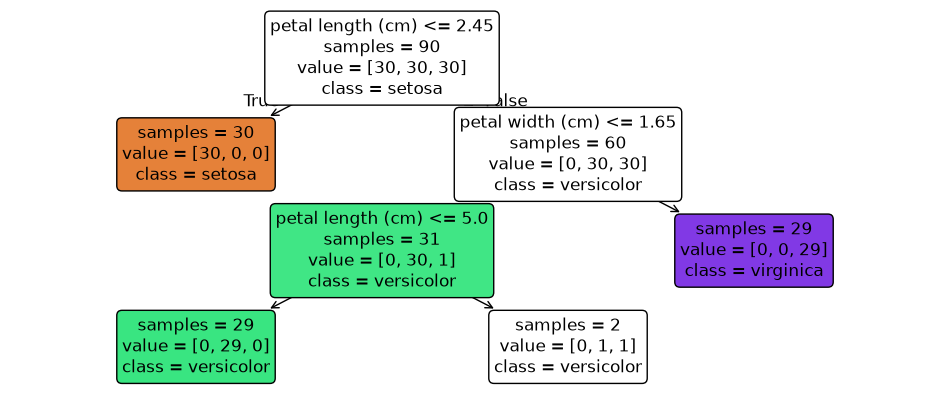

In [8]:
plt.figure(figsize=(12, 5))
plot_tree(model, feature_names=list(X.columns), class_names=list(iris.target_names),
          filled=True, rounded=True, proportion=False, impurity=False)
plt.show()

### 트리 깊이 바꾸기

`max_depth`는 트리가 질문을 이어갈 수 있는 깊이를 제한한다.

같은 학습·검증 데이터로 깊이 2와 4인 모델을 학습하고, 기준 모델인 깊이 3과 트리 구조·학습 정확도·검증 정확도를 비교한다.


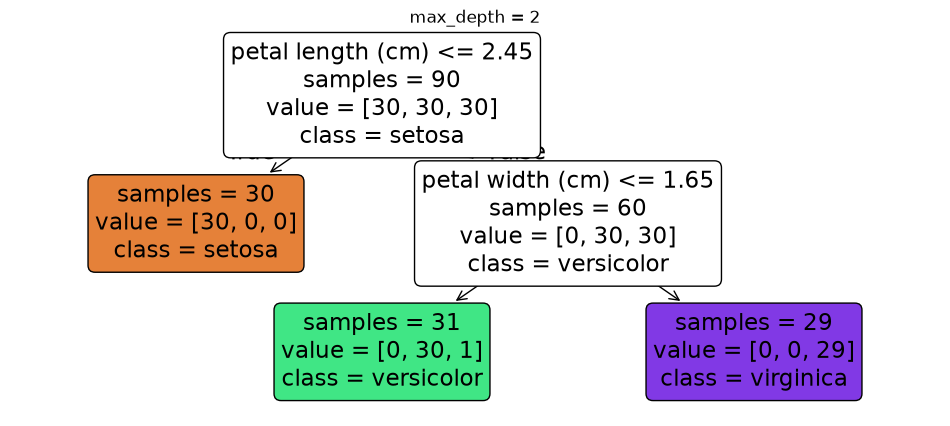

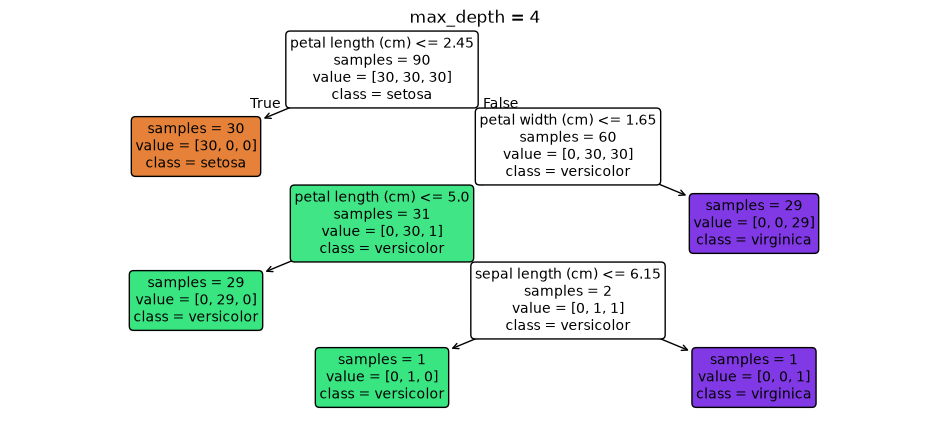

,max_depth,train_accuracy,val_accuracy
1,2,0.988889,0.900000
0,3,0.988889,0.900000
2,4,1.000000,0.933333


In [25]:
experiment_log = {
    model.max_depth: {
        "max_depth": model.max_depth,
        "model": model,
        "train_accuracy": accuracy_score(y_train, model.predict(X_train)),
        "val_accuracy": accuracy_score(y_val, model.predict(X_val)),
    }
}

for depth in [2, 4]:
    practice_model = DecisionTreeClassifier(max_depth=depth, random_state=SEED)
    practice_model.fit(X_train, y_train)

    experiment_log[depth] = {
        "max_depth": depth,
        "model": practice_model,
        "train_accuracy": accuracy_score(y_train, practice_model.predict(X_train)),
        "val_accuracy": accuracy_score(y_val, practice_model.predict(X_val)),
    }

    plt.figure(figsize=(12, 5))
    plot_tree(practice_model, feature_names=list(X.columns), class_names=list(iris.target_names),
              filled=True, rounded=True, proportion=False, impurity=False)
    plt.title(f"max_depth = {depth}")
    plt.show()

display(pd.DataFrame(experiment_log.values())
        [["max_depth", "train_accuracy", "val_accuracy"]].sort_values("max_depth"))


### 정확도 비교

트리가 깊어지면 학습 데이터의 세세한 특징까지 반영할 수 있다. 학습 데이터의 우연한 패턴까지 학습해 새 데이터의 예측 성능이 떨어지는 현상을 과적합이라고 한다.

깊이를 늘렸을 때 학습 정확도는 높아지고 검증 정확도는 낮아지는지 살펴본다.


### 최종 테스트

검증 정확도가 가장 높았던 깊이 4를 선택하고, 테스트 데이터로 최종 정확도를 평가한다.


In [19]:
final_model = experiment_log[4]["model"]
test_prediction = final_model.predict(X_test)
print("테스트 정확도:", accuracy_score(y_test, test_prediction))


테스트 정확도: 0.9333333333333333
